# Conditional Ablation Study

This CPU-only notebook reconstructs authenticated A–D ablation evidence from saved records. It never trains, samples, scores images, or changes frozen evidence. STEP 9B/10 values are retrospective supplementary applications of a fixed protocol, not a new held-out evaluation.

## 01 — Introduction & Research Questions

The exam question is whether a compact DDPM can follow structured avatar prompts and generalize to held-out compositions. Ablations separate **within-trajectory continuation** evidence from **observational** architecture/resolution comparisons: an observed difference is not automatically a causal effect.

## 02 — Experimental Design

Five conditional endpoints are considered: DDPM-C32-CA8-20k, DDPM-C32-CA8CA16-20k, DDPM-C32-CA8CA16-40k, DDPM-C64-CA8CA16-40k, and DDPM-C64-CA8CA16-60k. A changes decoder attention but also capacity and run; B and D are exact-state continuations; C changes resolution, backbone, preprocessing and evaluator input view together.

In [1]:
from __future__ import annotations
import json
from pathlib import Path
import matplotlib.pyplot as plt

from tiny_avatar_diffusion.captions import generate_caption
from tiny_avatar_diffusion.frozen_results import load_frozen_results
from tiny_avatar_diffusion.semantic_mapping import CANONICAL_ATTRIBUTE_ORDER, SEMANTIC_MAPPING

ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
STEP9B = ROOT / 'results/runs/v2a_step9b_final_supplementary_ema60k_v1/five_endpoint_comparison.json'
AUDIT = ROOT / 'docs/release/HISTORICAL_EVALUATION_AND_DECISION_AUDIT.md'
FIGURE_DIR = ROOT / 'docs/report/figures'
assert STEP9B.is_file() and AUDIT.is_file()
rows = json.loads(STEP9B.read_text(encoding='utf8'))
frozen = load_frozen_results(ROOT)
print(f'Loaded {len(rows)} authenticated STEP 9B endpoint rows and canonical DR04/DR05 frozen results.')

Loaded 5 authenticated STEP 9B endpoint rows and canonical DR04/DR05 frozen results.


In [2]:
endpoint_map = {r['endpoint']: r for r in rows}
endpoints = [
    {'id':'v1_conditional_20k','label':'DDPM-C32-CA8-20k','resolution':32,'architecture':'CA8','steps':20000,'source':'STEP 10 supplementary record'},
    {'id':'h7_conditional_20k','label':'DDPM-C32-CA8CA16-20k','resolution':32,'architecture':'CA8+CA16','steps':20000,'source':'STEP 10 supplementary record'},
    {'id':'h7_ca8_ca16','label':'DDPM-C32-CA8CA16-40k','resolution':32,'architecture':'CA8+CA16','steps':40000,'source':'STEP 9B supplementary record'},
    {'id':'v2_a_ca8_ca16','label':'DDPM-C64-CA8CA16-40k','resolution':64,'architecture':'CA8+CA16','steps':40000,'source':'STEP 9B supplementary record'},
    {'id':'v2_a_ema60k_supplementary','label':'DDPM-C64-CA8CA16-60k','resolution':64,'architecture':'CA8+CA16','steps':60000,'source':'STEP 9B supplementary record'},
]
# The two 20k rows are authenticated in the historical audit; do not fabricate unavailable fields.
historical_20k = {'v1_conditional_20k': {'kid_common32':.03919,'fid_common32':96.52,'maa_ood':.2950,'eam_ood':.000,'macro_psr_ood':.000}, 'h7_conditional_20k': {'kid_common32':.03648,'fid_common32':93.53,'maa_ood':.4013,'eam_ood':.010,'macro_psr_ood':.045}}
table=[]
for e in endpoints:
    record = endpoint_map.get(e['id'], historical_20k.get(e['id']))
    table.append({**e, **record})
try:
    import pandas as pd
    display(pd.DataFrame(table))
except ImportError:
    for row in table: print(row)

,id,label,resolution,architecture,steps,source,kid_common32,fid_common32,maa_ood,eam_ood,macro_psr_ood,scientific_name,endpoint,native_resolution,successful_updates,parameters,latency_seconds,peak_allocated_bytes,lpips_id,lpips_ood
0,v1_conditional_20k,DDPM-C32-CA8-20k,32,CA8,20000,STEP 10 supplementary record,0.039190,96.520000,0.2950,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,h7_conditional_20k,DDPM-C32-CA8CA16-20k,32,CA8+CA16,20000,STEP 10 supplementary record,0.036480,93.530000,0.4013,0.010,0.045,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,h7_ca8_ca16,DDPM-C32-CA8CA16-40k,32,CA8+CA16,40000,STEP 9B supplementary record,0.010000,59.430432,0.9650,0.860,0.895,Decoder-Enhanced,h7_ca8_ca16,32.0,40000.0,4749059.0,9.123690,31368704.0,0.028743,0.026561
3,v2_a_ca8_ca16,DDPM-C64-CA8CA16-40k,64,CA8+CA16,40000,STEP 9B supplementary record,0.027882,75.378553,0.6450,0.055,0.385,High-Resolution Extension,v2_a_ca8_ca16,64.0,40000.0,5230403.0,10.343386,38474240.0,0.108116,0.103626
4,v2_a_ema60k_supplementary,DDPM-C64-CA8CA16-60k,64,CA8+CA16,60000,STEP 9B supplementary record,0.016694,65.007073,0.9800,0.920,0.960,High-Resolution Extension,v2_a_ema60k_supplementary,64.0,60000.0,5230403.0,9.185466,38474240.0,0.095535,0.089085


## 03 — Evaluation Protocol

STEP 9B/10 fixes 40 ID and 40 compositional-OOD prompts, five seeds per prompt, hence 400 generated images per endpoint. The later dual-view evaluator routes native32 through official 32px then bilinear 64px, and native64 directly. Common-32 KID/FID uses a defined resize route. Quality, adherence and diversity therefore answer different questions and are comparable only under the recorded contract.

## 04 — Metrics

For attributes \(a=1,\ldots,4\), **MAA** is the mean atomic correctness: \(MAA=\frac{1}{4N}\sum_{i,a}1[\hat y_{ia}=y_{ia}]\). **EAM** is exact four-attribute match. MacroPSR averages pair-success rates across OOD families. KID and FID compare generated and reference feature distributions; lower is better. LPIPS averages perceptual distance between seed-paired images; it is diversity, not prompt adherence. Implementations and frozen loading are in `frozen_results.py`, evaluator modules, and the saved protocol records.

## 05 — Ablation A: CA8 vs CA8+CA16

**Motivation/design.** A compares the two 20k native32 conditional endpoints under the later standardized panel. **Observed result.** OOD adherence is plotted below. **Interpretation/limits.** It motivates CA16, not a CA16-only causal estimate: runs are independent and CA16 adds 25,152 parameters.

## 06 — Ablation B: Native32 Continuation

B is the DDPM-C32-CA8CA16 20k→40k exact-state continuation: model, EMA, optimizer, scaler, RNG and data position continue rather than restart. The 40k row is a later STEP 9B supplementary measurement. The historical evaluator binding for the original decision is not retroactively resolved by that later protocol.

## 07 — Ablation C: Native32 vs Native64

C compares DDPM-C32-CA8CA16-40k and DDPM-C64-CA8CA16-40k descriptively. Resolution, backbone, preprocessing, trajectory and evaluator input view all change. Consequently, neither the plotted adherence values nor Common-32 KID/FID estimate an isolated resolution effect.

## 08 — Ablation D: Native64 Continuation

D compares DDPM-C64-CA8CA16-40k→60k via exact continuation. The saved STEP 9B values move from OOD MAA/EAM/MacroPSR .645/.055/.385 to .980/.920/.960; KID/FID Common-32 move from .027882/75.379 to .016694/65.007. These are observed supplementary results, with documented native64 evaluator background sensitivity.

## 09 — Cross-Ablation Comparison

The following figures are generated only from the compact five-endpoint record and the two audit-authenticated 20k rows. They visually group all rows but do not license cross-protocol causal ranking.

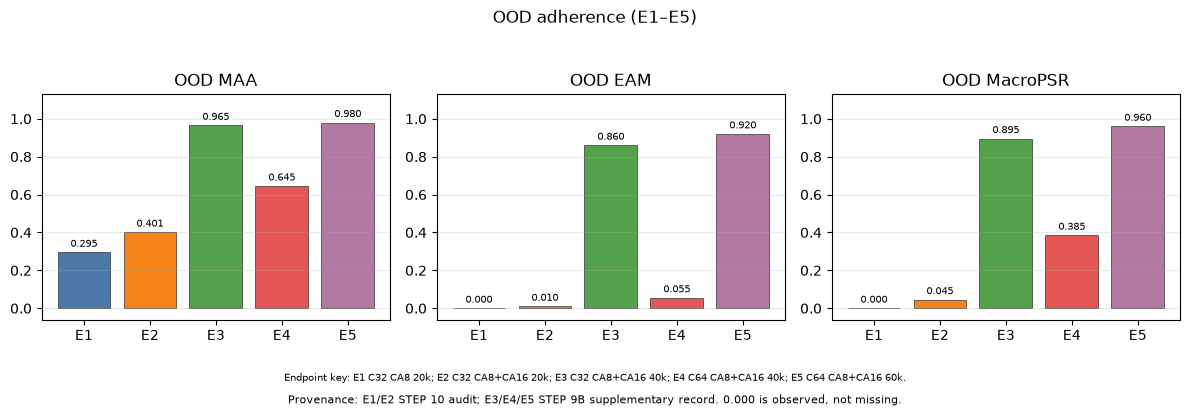

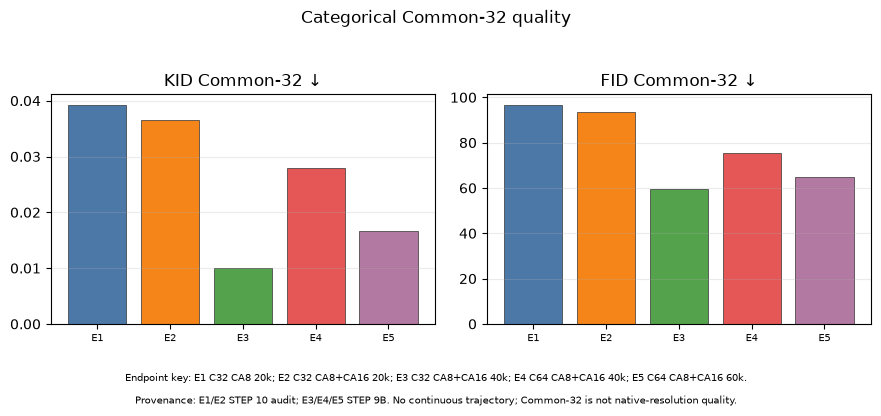

In [3]:
short_labels=['E1','E2','E3','E4','E5']
colors=['#4c78a8','#f58518','#54a24b','#e45756','#b279a2']
metrics=[('maa_ood','OOD MAA'),('eam_ood','OOD EAM'),('macro_psr_ood','OOD MacroPSR')]
fig, axes=plt.subplots(1,3,figsize=(12,4.1))
for ax,(key,title) in zip(axes,metrics):
    values=[r[key] for r in table]; ax.bar(range(5),values,color=colors,edgecolor='#333333',linewidth=.5)
    for x,value in enumerate(values): ax.annotate(f'{value:.3f}',(x,value),xytext=(0,4),textcoords='offset points',ha='center',fontsize=7)
    ax.set(title=title,ylim=(-.06,1.13),xticks=range(5),xticklabels=short_labels); ax.grid(axis='y',alpha=.25)
fig.suptitle('OOD adherence (E1–E5)')
fig.text(.5,.075,'Endpoint key: E1 C32 CA8 20k; E2 C32 CA8+CA16 20k; E3 C32 CA8+CA16 40k; E4 C64 CA8+CA16 40k; E5 C64 CA8+CA16 60k.',ha='center',fontsize=7)
fig.text(.5,.02,'Provenance: E1/E2 STEP 10 audit; E3/E4/E5 STEP 9B supplementary record. 0.000 is observed, not missing.',ha='center',fontsize=8)
fig.tight_layout(rect=(0,.13,1,.94))
for ext in ('png','pdf'): fig.savefig(FIGURE_DIR/f'conditional_ablation_ood_metrics.{ext}',dpi=300,bbox_inches='tight')
plt.show()
fig,axes=plt.subplots(1,2,figsize=(9,4.1))
for ax,key,title in zip(axes,['kid_common32','fid_common32'],['KID Common-32 ↓','FID Common-32 ↓']):
    values=[r[key] for r in table]; ax.bar(range(5),values,color=colors,edgecolor='#333333',linewidth=.5)
    ax.set(title=title,xticks=range(5),xticklabels=short_labels); ax.tick_params(axis='x',labelsize=7); ax.grid(axis='y',alpha=.25)
fig.suptitle('Categorical Common-32 quality')
fig.text(.5,.075,'Endpoint key: E1 C32 CA8 20k; E2 C32 CA8+CA16 20k; E3 C32 CA8+CA16 40k; E4 C64 CA8+CA16 40k; E5 C64 CA8+CA16 60k.',ha='center',fontsize=7)
fig.text(.5,.02,'Provenance: E1/E2 STEP 10 audit; E3/E4/E5 STEP 9B. No continuous trajectory; Common-32 is not native-resolution quality.',ha='center',fontsize=7.5)
fig.tight_layout(rect=(0,.13,1,.94))
for ext in ('png','pdf'): fig.savefig(FIGURE_DIR/f'conditional_ablation_common32_quality.{ext}',dpi=300,bbox_inches='tight')
plt.show()

## 10 — Qualitative Evidence

The optional 4×5 gallery below is **new qualitative inference**, not a STEP 9B/10 record or a benchmark. It covers all five quantitative endpoints, including the recovered EMA milestone `DDPM-C32-CA8CA16-20k`. CA8 and CA8+CA16 at 20k use seed-paired, from-scratch initialization with equal shared initial parameters plus the additional CA16 parameters. The native32 20k→40k and native64 40k→60k comparisons are authenticated continuations; comparisons across native32/native64 are not causally isolated. Twenty images cannot support a statistical conclusion or conceal observed conditioning failures.

**Endpoint key:** E1 = DDPM-C32-CA8-20k; E2 = DDPM-C32-CA8CA16-20k; E3 = DDPM-C32-CA8CA16-40k; E4 = DDPM-C64-CA8CA16-40k; E5 = DDPM-C64-CA8CA16-60k.

**Canonical row captions:** OOD1 `avatar face_shape_oval glasses_rimless_glasses hair_color_blue_gray face_color_golden_tan`; OOD2 `avatar face_shape_round glasses_no_glasses hair_color_dark_brown face_color_peach_tan`; OOD3 `avatar face_shape_pointed glasses_heart_glasses hair_color_black face_color_pale_pink`; OOD4 `avatar face_shape_pointed glasses_oversized_glasses hair_color_light_blond face_color_deep_brown`.

The nominal seed is shared, but initial noise is not identical across architectures or native resolutions. Enabling the cell saves new samples and a provenance manifest under `results/qualitative/`; it never changes frozen results.

In [4]:
# Opt-in only: this cell performs 20 new 1,000-step qualitative samples when set to True.
RUN_QUALITATIVE_INFERENCE = False
QUALITATIVE_SEED = 2026
QUALITATIVE_DIR = ROOT / 'results' / 'qualitative' / 'conditional_ablation_ood_4x5_seed2026'
CA16_20K = ROOT.parent / 'DL_Project_CA16' / 'results' / 'runs' / 'ca16_ablation_ca8_ca16_seed2026' / 'milestone_20000.pt'
CA16_20K_SHA256 = 'ad3093446be3958d322d7af9d1109636e50e0fa7decc766177f015d04b51848d'
NATIVE64_40K = ROOT / 'results' / 'v2_a_matched_budget_seed20261017' / 'checkpoint_success_040000.pt'
NATIVE64_40K_SHA256 = '15cb3cfc580e549a748aadac513ca90e2d588b281b46fc59b15e1b267ccc54f2'
OOD_FAMILIES = [
    ('OOD1', {'face_shape': 2, 'glasses': 3, 'hair_color': 8, 'face_color': 4}),
    ('OOD2', {'face_shape': 4, 'glasses': 11, 'hair_color': 6, 'face_color': 7}),
    ('OOD3', {'face_shape': 0, 'glasses': 10, 'hair_color': 7, 'face_color': 10}),
    ('OOD4', {'face_shape': 0, 'glasses': 0, 'hair_color': 0, 'face_color': 0}),
]
base_attributes = {name: min(SEMANTIC_MAPPING[name]) for name in CANONICAL_ATTRIBUTE_ORDER}
ood_prompts = [(name, {**base_attributes, **overrides}) for name, overrides in OOD_FAMILIES]
ood_captions = {name: generate_caption(values) for name, values in ood_prompts}
assert all(len(caption.split()) == 5 for caption in ood_captions.values())
print('Canonical OOD captions:', ood_captions)
if RUN_QUALITATIVE_INFERENCE:
    import hashlib
    from types import SimpleNamespace
    import torch
    from tiny_avatar_diffusion.inference import (
        PromptAttributes, generate_conditional, load_conditional_bundle, load_h7_conditional_bundle,
        _load_tokenizer, resolve_device, sha256_file,
    )
    from tiny_avatar_diffusion.v2_native64 import make_v2_model, parameter_count
    from tiny_avatar_diffusion.unet import ConditionalTinyUNet
    from tiny_avatar_diffusion.text_conditioning import TextConditioningConfig, TextConditioningEncoder
    from tiny_avatar_diffusion.diffusion import LinearDDPMSchedule
    from tiny_avatar_diffusion.v2_release import generate_v2_native64
    device = resolve_device('auto')
    if sha256_file(CA16_20K) != CA16_20K_SHA256:
        raise ValueError('CA8+CA16 20k source checkpoint SHA-256 mismatch')
    ca16_20k = torch.load(CA16_20K, map_location='cpu', weights_only=True)
    experiment20, progress20 = ca16_20k.get('experiment', {}), ca16_20k.get('progress', {})
    if ca16_20k.get('schema') != 'ca16_ablation_main_training_v1' or ca16_20k.get('run_id') != 'ca16_ablation_ca8_ca16_seed2026' or experiment20.get('architecture_arm') != 'ca8_ca16' or experiment20.get('use_decoder16_cross_attention') is not True or progress20.get('step') != 20000 or experiment20.get('frozen_training',{}).get('resolution') != (32,32) or set(ca16_20k.get('ema_state_dict',{})) != {'text_encoder','conditional_unet'}:
        raise ValueError('CA8+CA16 20k source identity, architecture, progress, or EMA mismatch')
    text20 = TextConditioningEncoder(TextConditioningConfig()); model20 = ConditionalTinyUNet(dropout=0.0, use_decoder16_cross_attention=True)
    text20.load_state_dict(ca16_20k['ema_state_dict']['text_encoder'], strict=True); model20.load_state_dict(ca16_20k['ema_state_dict']['conditional_unet'], strict=True)
    if sum(p.numel() for p in text20.parameters()) + sum(p.numel() for p in model20.parameters()) != 4749059:
        raise ValueError('CA8+CA16 20k EMA architecture mismatch')
    text20.to(device).eval(); model20.to(device).eval()
    bundle20 = SimpleNamespace(model=model20, text_encoder=text20, tokenizer=_load_tokenizer(), schedule=LinearDDPMSchedule().to(device).eval(), device=device, requested_device=device.type, model_identity='ca8_ca16_20k_ema')
    if sha256_file(NATIVE64_40K) != NATIVE64_40K_SHA256:
        raise ValueError('Native64 40k checkpoint SHA-256 mismatch')
    native64 = torch.load(NATIVE64_40K, map_location='cpu', weights_only=True)
    expected_config = {'variant':'v2_a','run_id':'v2_a_native64_matched_batch32_seed20261017','successful_updates':40000,'microbatch_size':8,'gradient_accumulation':4,'seed':20261017,'lr':0.0002,'weight_decay':0.0,'ema_decay':0.9999,'resolution':64,'checkpoint_interval_updates':5000,'max_grad_norm':None}
    if native64.get('schema') != 'tiny_avatar_diffusion.v2a_matched_budget_training_v1' or native64.get('config') != expected_config or set(native64.get('ema', {})) != {'model','text'}:
        raise ValueError('Native64 40k provenance or EMA state mismatch')
    _, model64 = make_v2_model('v2_a'); text64 = TextConditioningEncoder(TextConditioningConfig())
    model64.load_state_dict(native64['ema']['model'], strict=True); text64.load_state_dict(native64['ema']['text'], strict=True)
    if parameter_count(model64, text64) != {'denoiser':5127427,'text_encoder':102976,'total':5230403}:
        raise ValueError('Native64 40k architecture mismatch')
    model64.to(device).eval(); text64.to(device).eval()
    bundle64 = SimpleNamespace(model=model64, text_encoder=text64, tokenizer=_load_tokenizer(), schedule=LinearDDPMSchedule().to(device).eval(), device=device)
    from tiny_avatar_diffusion.v2a_ema60_release import load_v2a_conditional_ema60
    endpoints = [
        {'label':'DDPM-C32-CA8-20k','weight_variant':'EMA','resolution':32,'checkpoint_path':'artifacts/checkpoints/conditional_main_ema_step20000.pt','checkpoint_sha256':sha256_file(ROOT/'artifacts'/'checkpoints'/'conditional_main_ema_step20000.pt'),'configuration':'native32 CA8','bundle':load_conditional_bundle(device.type)},
        {'label':'DDPM-C32-CA8CA16-20k','weight_variant':'EMA','resolution':32,'checkpoint_path':str(CA16_20K),'checkpoint_sha256':CA16_20K_SHA256,'configuration':'native32 CA8+CA16','bundle':bundle20},
        {'label':'DDPM-C32-CA8CA16-40k','weight_variant':'EMA','resolution':32,'checkpoint_path':'artifacts/checkpoints/ddpm-c32-ema-40k.pt','checkpoint_sha256':sha256_file(ROOT/'artifacts'/'checkpoints'/'ddpm-c32-ema-40k.pt'),'configuration':'native32 CA8+CA16','bundle':load_h7_conditional_bundle(device.type)},
        {'label':'DDPM-C64-CA8CA16-40k','weight_variant':'EMA','resolution':64,'checkpoint_path':str(NATIVE64_40K),'checkpoint_sha256':NATIVE64_40K_SHA256,'configuration':'native64 CA8+CA16','bundle':bundle64},
        {'label':'DDPM-C64-CA8CA16-60k','weight_variant':'EMA','resolution':64,'checkpoint_path':'artifacts/checkpoints/ddpm-c64-ema-60k.pt','checkpoint_sha256':sha256_file(ROOT/'artifacts'/'checkpoints'/'ddpm-c64-ema-60k.pt'),'configuration':'native64 CA8+CA16','bundle':load_v2a_conditional_ema60(device.type)},
    ]
    QUALITATIVE_DIR.mkdir(parents=True, exist_ok=True)
    manifest = {'schema':'tiny_avatar_diffusion.qualitative_ood_gallery_v1','kind':'new_qualitative_samples','seed':QUALITATIVE_SEED,'sampler':'ancestral_ddpm_1000_steps','selection_criterion':'OOD1/OOD2 use matching frozen sealed-case captions satisfying the requested diversity constraints; OOD3 uses the lowest valid dark-hair raw ID with the family pair and without another OOD pair; OOD4 preserves the prior fixed caption. No generated image or metric informed selection.','selection_sources':{'OOD1':'data/processed/reduced_four_model_benchmark_v3/sealed_case_manifest.json: cs10239298051463707286','OOD2':'data/processed/reduced_four_model_benchmark_v3/sealed_case_manifest.json: cs10508005514331529038','OOD3':'semantic_mapping.py deterministic raw-ID rule','OOD4':'previous qualitative gallery fixed caption'},'endpoints':[{key:value for key,value in endpoint.items() if key != 'bundle'} for endpoint in endpoints],'rows':[], 'note':'Same nominal seed; distinct architecture/resolution means non-identical initial noise.'}
    images = {}
    for row_name, values in ood_prompts:
        attrs = PromptAttributes(**values)
        for endpoint in endpoints:
            image = (generate_v2_native64(endpoint['bundle'], caption=attrs.caption, seed=QUALITATIVE_SEED) if endpoint['resolution'] == 64 else generate_conditional(endpoint['bundle'], seed=QUALITATIVE_SEED, attributes=attrs).image)
            filename = f"{row_name}__{endpoint['label'].lower().replace('-', '_')}.png"; output = QUALITATIVE_DIR / filename; image.save(output)
            images[(row_name, endpoint['label'])] = image
            manifest['rows'].append({'ood_family':row_name,'caption':attrs.caption,'attributes':values,**{key:value for key,value in endpoint.items() if key != 'bundle'},'seed':QUALITATIVE_SEED,'output_path':str(output.relative_to(ROOT)),'png_sha256':sha256_file(output)})
    (QUALITATIVE_DIR/'provenance_manifest.json').write_text(json.dumps(manifest, indent=2)+'\n', encoding='utf-8')
    endpoint_codes = {endpoint['label']: f'E{index}' for index, endpoint in enumerate(endpoints, start=1)}
    fig, axes = plt.subplots(4,5,figsize=(12.6,8.6),gridspec_kw={'wspace':.03,'hspace':.07})
    for r,(row_name, _) in enumerate(ood_prompts):
        for c,endpoint in enumerate(endpoints):
            axes[r,c].imshow(images[(row_name,endpoint['label'])].resize((128,128))); axes[r,c].axis('off')
            if r == 0: axes[r,c].set_title(endpoint_codes[endpoint['label']], fontsize=11, fontweight='bold', pad=6)
        axes[r,0].text(-.11,.5,row_name,transform=axes[r,0].transAxes,ha='right',va='center',fontsize=10,fontweight='bold')
    fig.suptitle('Qualitative compositional OOD examples — seed 2026, ancestral DDPM 1,000 steps', fontsize=12)
    fig.tight_layout(rect=(.04,0,1,.95))
    for ext in ('png','pdf'): fig.savefig(FIGURE_DIR/f'conditional_ablation_ood_4x5_seed2026.{ext}', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('Qualitative OOD inference disabled by default; no images, manifest, or gallery are generated.')

Canonical OOD captions: {'OOD1': 'avatar face_shape_oval glasses_rimless_glasses hair_color_blue_gray face_color_golden_tan', 'OOD2': 'avatar face_shape_round glasses_no_glasses hair_color_dark_brown face_color_peach_tan', 'OOD3': 'avatar face_shape_pointed glasses_heart_glasses hair_color_black face_color_pale_pink', 'OOD4': 'avatar face_shape_pointed glasses_oversized_glasses hair_color_light_blond face_color_deep_brown'}
Qualitative OOD inference disabled by default; no images, manifest, or gallery are generated.


## 11 — Interpretation and Scientific Limitations

The continuation comparisons support improvement along their authenticated trajectories. A motivates CA16 but remains confounded by capacity and independent training. C is explicitly multi-factor. Evaluator scores depend on calibration, image route and documented native64 background sensitivity; compositional prompt success is narrower than open-ended semantic generalization.

## 12 — Conclusions

A–D establish a traceable progression: CA16 is a historically motivated intervention, additional optimization is associated with improved saved endpoint results, and native64 changes are descriptive rather than isolated causal evidence. All quantitative statements above are tied to saved STEP 9B/10 or frozen DR04/DR05 records; no new experimental conclusion is introduced.

## Qualitative Comparison — Four Compositional OOD Families Across Five Conditional Endpoints

This display loads the authenticated exported grid directly; it is independent of the optional GPU inference cell above. The grid is qualitative evidence only: shared nominal seed does not imply identical initial noise across architectures or resolutions. In particular, the visible OOD4 outputs retain observable conditioning errors, including imperfect reproduction of the requested light-blond hair in native64 outputs.

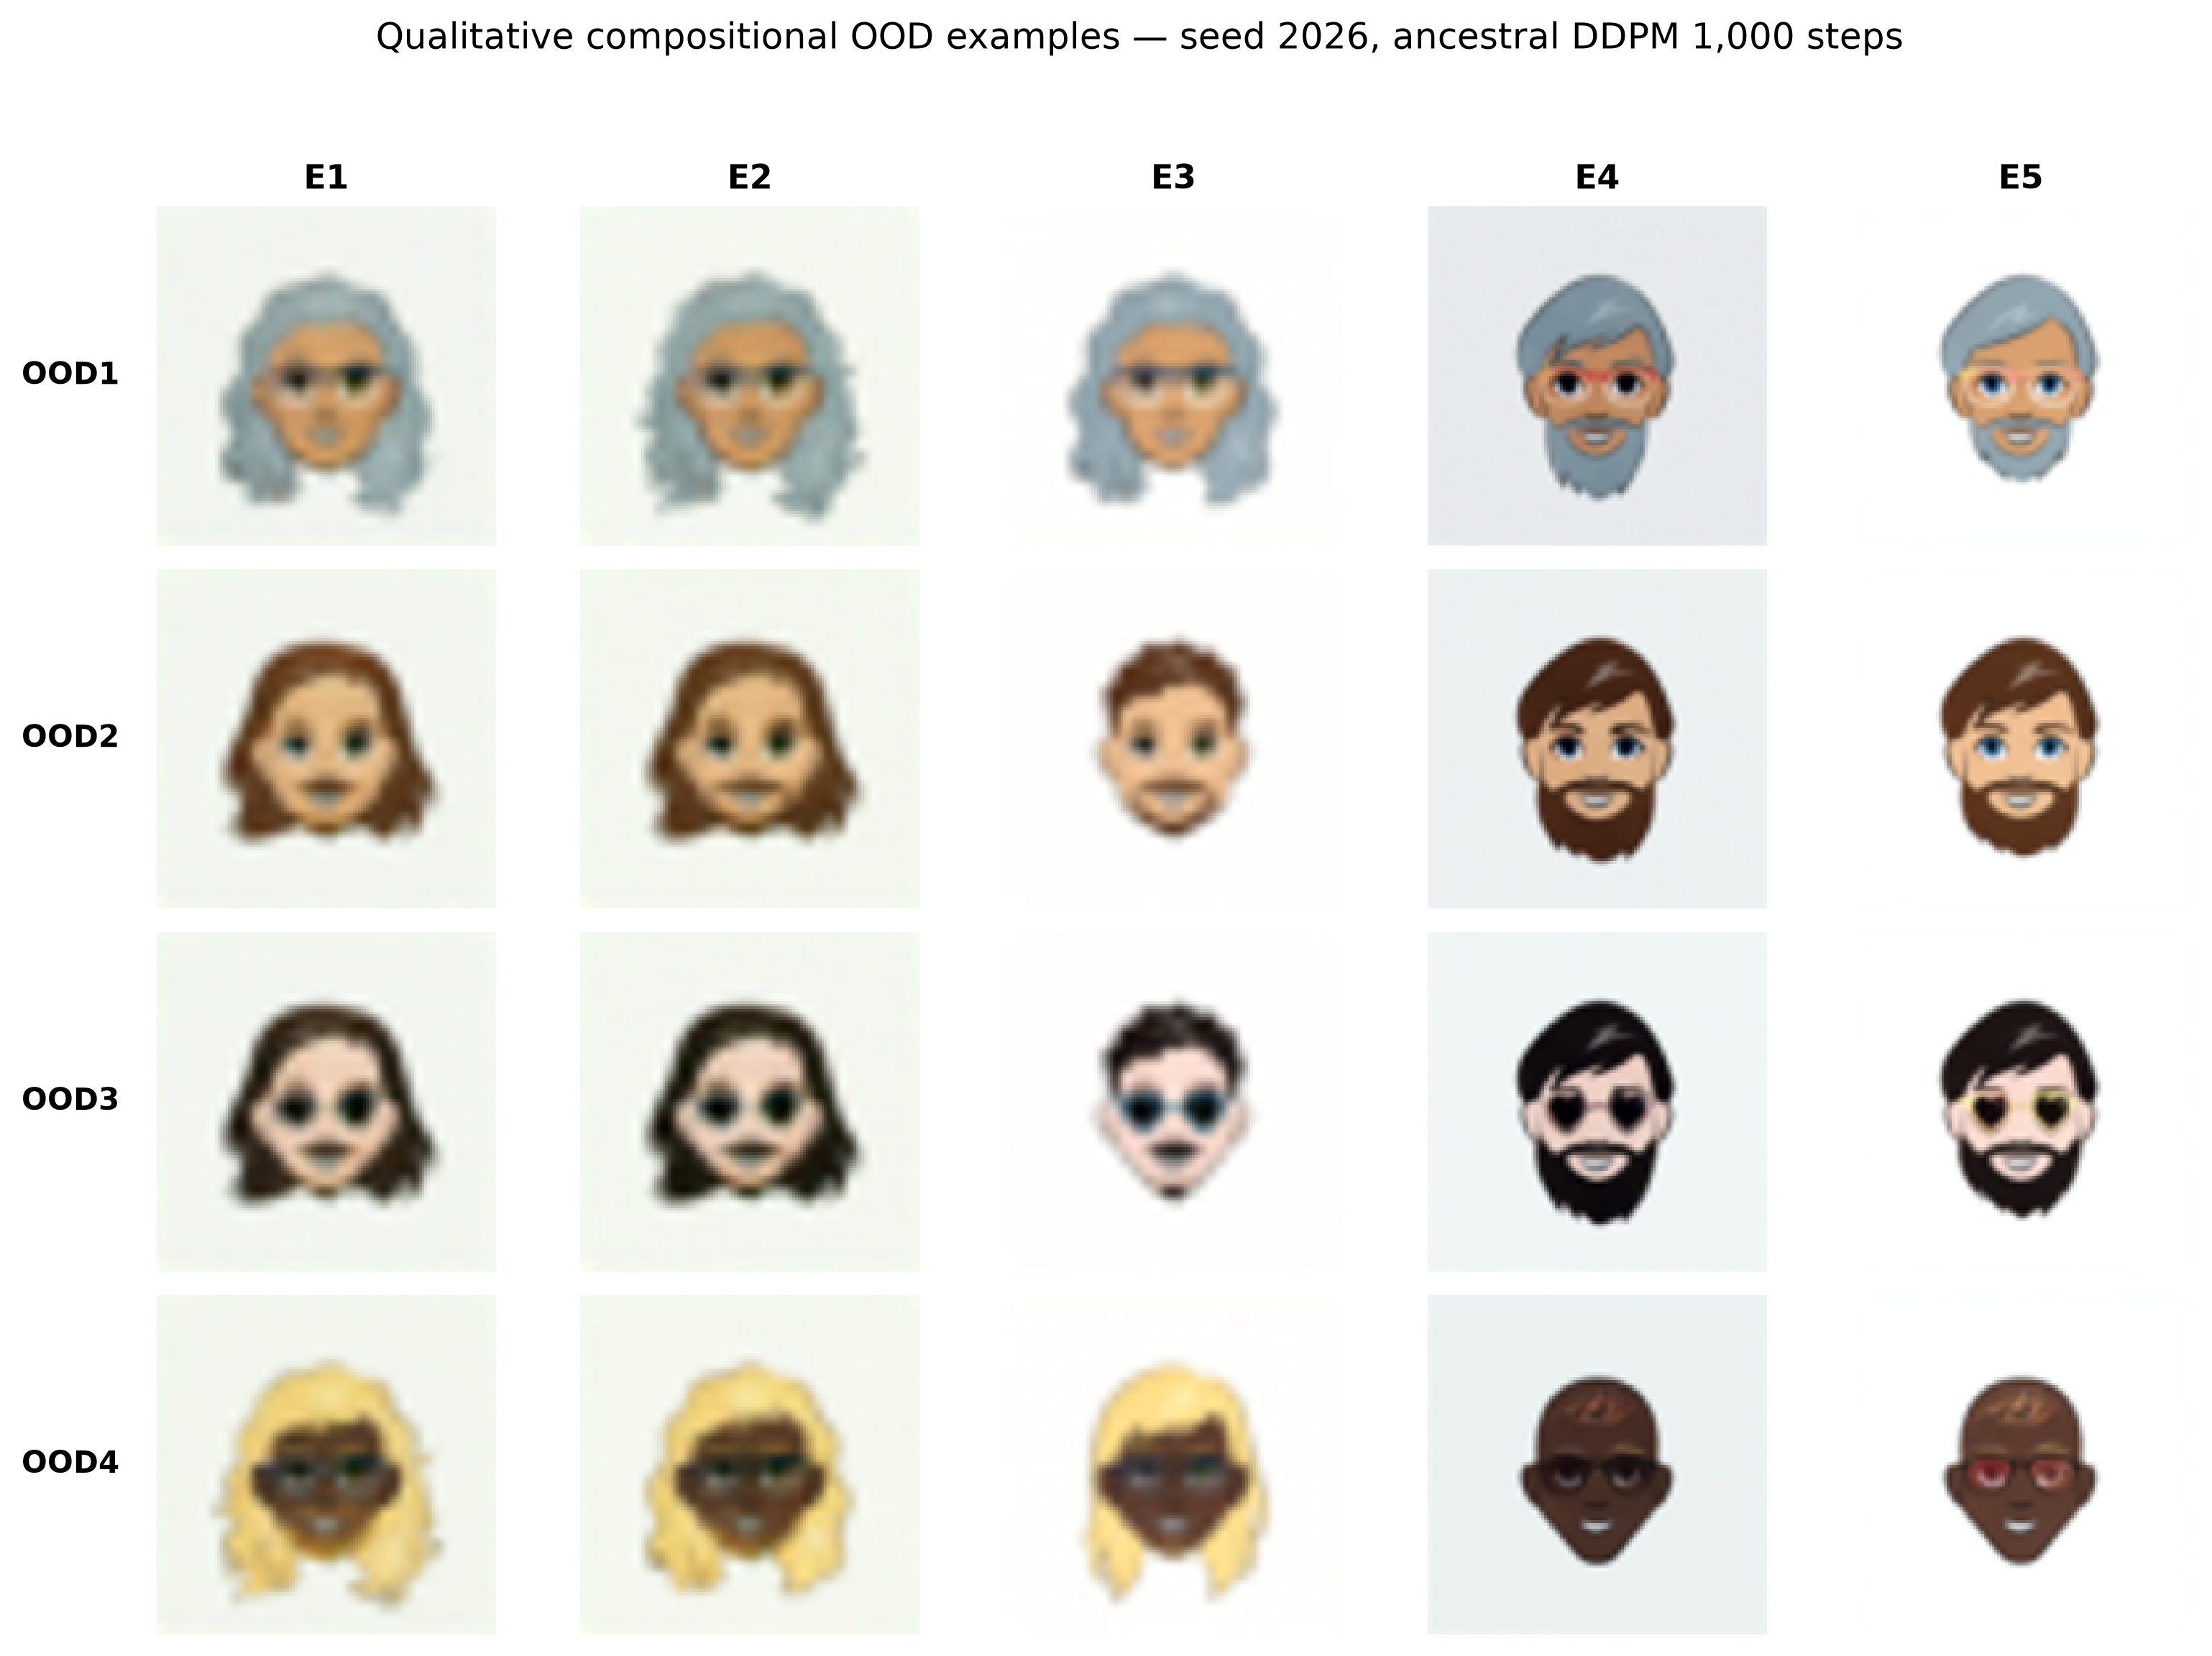

**Endpoint mapping**
- E1 — DDPM-C32-CA8-20k
- E2 — DDPM-C32-CA8CA16-20k
- E3 — DDPM-C32-CA8CA16-40k
- E4 — DDPM-C64-CA8CA16-40k
- E5 — DDPM-C64-CA8CA16-60k

**Canonical OOD captions**
- **OOD1** — `avatar face_shape_oval glasses_rimless_glasses hair_color_blue_gray face_color_golden_tan`
- **OOD2** — `avatar face_shape_round glasses_no_glasses hair_color_dark_brown face_color_peach_tan`
- **OOD3** — `avatar face_shape_pointed glasses_heart_glasses hair_color_black face_color_pale_pink`
- **OOD4** — `avatar face_shape_pointed glasses_oversized_glasses hair_color_light_blond face_color_deep_brown`

Scientific note: visual progression is illustrative rather than a ranking; the endpoints differ in architecture, resolution and training trajectory. OOD4 retains visible conditioning failures, so no sample has been replaced or selected to hide them.


In [5]:
from PIL import Image
from IPython.display import Markdown, display

OOD_GRID = ROOT / 'docs' / 'report' / 'figures' / 'conditional_ablation_ood_4x5_seed2026.png'
OOD_MANIFEST = ROOT / 'results' / 'qualitative' / 'conditional_ablation_ood_4x5_seed2026' / 'provenance_manifest.json'
assert OOD_GRID.is_file(), f'Missing released qualitative grid: {OOD_GRID}'
assert OOD_MANIFEST.is_file(), f'Missing qualitative provenance manifest: {OOD_MANIFEST}'
ood_manifest = json.loads(OOD_MANIFEST.read_text(encoding='utf-8'))
assert len(ood_manifest['rows']) == 20
display(Image.open(OOD_GRID))
endpoint_key = ['DDPM-C32-CA8-20k', 'DDPM-C32-CA8CA16-20k', 'DDPM-C32-CA8CA16-40k', 'DDPM-C64-CA8CA16-40k', 'DDPM-C64-CA8CA16-60k']
captions = {}
for row in ood_manifest['rows']:
    captions.setdefault(row['ood_family'], row['caption'])
assert list(captions) == ['OOD1', 'OOD2', 'OOD3', 'OOD4']
mapping = '\n'.join(f'- E{i} — {label}' for i, label in enumerate(endpoint_key, start=1))
caption_text = '\n'.join(f'- **{family}** — `{caption}`' for family, caption in captions.items())
display(Markdown('**Endpoint mapping**\n' + mapping + '\n\n**Canonical OOD captions**\n' + caption_text))
print('Scientific note: visual progression is illustrative rather than a ranking; the endpoints differ in architecture, resolution and training trajectory. OOD4 retains visible conditioning failures, so no sample has been replaced or selected to hide them.')